# Task 1: Explore Weather Patterns
## Singapore Rainfall, 2017–2024

This notebook explores rainfall patterns across Singapore from 2017 to 2024, examining how rainfall varies within a year and how these patterns differ across years and monitoring stations.

The analysis investigates:

- **Seasonal patterns:** Which months typically experience more or less rainfall?
- **Annual differences:** How do rainfall amounts and monthly patterns vary across years?
- **Time-of-day patterns:** When does rainfall occur, and does this change with the season?
- **Rainfall frequency and intensity:** Are wetter periods associated with more frequent rain, larger rainfall amounts, or both?
- **Spatial variation:** How do rainfall patterns differ between stations?

Building on the preceding data preparation, observation coverage is assessed and rainfall is aggregated at station level before comparisons are made. Visualisations and summary statistics are used to present the findings and discuss their limitations.

The findings also inform **Task 2: Predict Rainfall** by motivating candidate predictors such as station identity, month, hour and recent rainfall history for estimating the probability of exceeding a specified rainfall amount in the next 30 minutes.

## 1.1 Spark Session

In [1]:
import socket
from pyspark.sql import SparkSession
from pyspark.sql import Window

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pyspark.sql.functions as F
import seaborn as sns
import pandas as pd

import os
import sys

In [2]:
spark = SparkSession.builder.getOrCreate()

spark.conf.set("spark.sql.session.timeZone", "Asia/Singapore")

print("Running on:   ", socket.gethostname())
print("Spark master: ", spark.sparkContext.master)
print("Spark version:", spark.version)

Running on:    rainfall-ashley-1-m
Spark master:  yarn
Spark version: 3.5.3


In [3]:
# Constants for Central Coordinates and Rainfall Multiplier per Day
# There are 12 five-minute intervals per hour and 24 hours per day
C_LAT, C_LON = 1.3521, 103.8198 
RF_MULTIPLIER = (24 * 60) / 5

## 1.2 Reading the Cleaned Rainfall Data

In [4]:
rain = spark.read.parquet("gs://dsa5208-rainfall-sixing-data/parquet/")

## 1.3 Seasonal Patterns: Which Months Are Wetter or Drier?

This section examines the typical monthly rainfall pattern across 2017–2024. Estimated rainfall is first calculated for each year–month, then averaged across years to produce a January–December profile.

The resulting chart shows which calendar months tend to be wetter or drier during the study period. These estimates are based on available observations and may be affected by missing records and changes in the reporting stations.

In [5]:
# Step 1: Extract the year and month from the observation date
rain = (
    rain.withColumn("date", F.to_date("date"))
        .withColumn("year", F.year("date"))
        .withColumn("month", F.month("date"))
)

# Step 2: Calculate mean rainfall per observed five-minute interval
# for each year and month
monthly_spk = (
    rain.filter(F.col("year").between(2017, 2024))
        .groupBy("year", "month")
        .agg(
            F.avg("reading_value").alias("mean_per_interval"),
            F.countDistinct("station_id").alias("n_stations")
        )
        .withColumn(
            "year_month",
            F.make_date("year", "month", F.lit(1))
        )
        .withColumn(
            "days",
            F.dayofmonth(F.last_day("year_month"))
        )
        # mean interval rainfall × expected intervals in the month
        .withColumn(
            "avg_rainfall_monthly",
            F.col("mean_per_interval") * F.col("days") * RF_MULTIPLIER
        )
        .orderBy("year_month")
)

+-----+---------------------+-------+
|month|mean_monthly_rainfall|n_years|
+-----+---------------------+-------+
|1    |242.71399146322779   |8      |
|2    |138.03910167348292   |8      |
|3    |204.13985689807674   |8      |
|4    |247.7985715439945    |8      |
|5    |217.79066209049319   |8      |
|6    |234.69007672407616   |8      |
|7    |148.52206350834757   |8      |
|8    |162.49473659015572   |8      |
|9    |207.5473359865546    |8      |
|10   |208.78946914642066   |8      |
|11   |312.5108928978004    |8      |
|12   |262.27824664072386   |8      |
+-----+---------------------+-------+



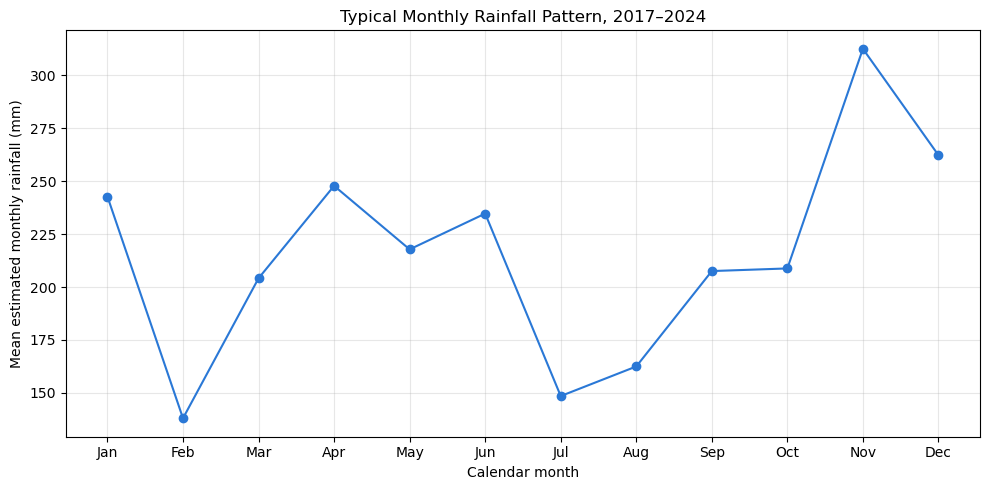

In [6]:
# Step 3: Average each calendar month's estimate across years
# For example, average January 2017, January 2018, ..., January 2024
seasonal_spk = (
    monthly_spk.groupBy("month")
        .agg(
            F.avg("avg_rainfall_monthly").alias("mean_monthly_rainfall"),
            F.countDistinct("year").alias("n_years")
        )
        .orderBy("month")
)

seasonal_spk.show(12, truncate=False)

# Step 4: Convert the small monthly summary to pandas
seasonal_df = seasonal_spk.toPandas()

# Step 5: Plot the January–December rainfall profile
month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    seasonal_df["month"],
    seasonal_df["mean_monthly_rainfall"],
    marker="o",
    color="#2a78d6"
)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_labels)
ax.set_xlabel("Calendar month")
ax.set_ylabel("Mean estimated monthly rainfall (mm)")
ax.set_title("Typical Monthly Rainfall Pattern, 2017–2024")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- **November has the highest mean estimated rainfall**, at approximately **310 mm**, followed by December at around **260 mm**.
- **February is the driest month on average**, at approximately **140 mm**. July and August also have relatively low rainfall.
- Rainfall rises from February to April, fluctuates through June, and drops sharply in July. It then generally increases towards the November peak.
- The pattern suggests **seasonal variation**, with wetter conditions towards the end of the year and relatively drier conditions in February and July–August.
- These values are averages across **2017–2024**. They do not mean that November was the wettest month in every year. The next section examines how rainfall differs between individual years.

## 1.4 Annual and Monthly Differences: How Does Rainfall Vary Across 2017–2024?

Section 1.3 summarised the typical seasonal pattern. This section compares individual years, then examines monthly rainfall within each year to identify wetter periods, drier periods and unusual peaks.

### 1.4.1 Which Years Have Higher or Lower Estimated Rainfall?

Estimated annual rainfall is calculated by scaling the mean recorded five-minute rainfall amount to the number of five-minute intervals in each year.

The bar chart compares these estimates across 2017–2024. The number of stations contributing observations is displayed above each bar for context; it does not indicate that every station reported continuously throughout the year.

Missing observations and changes in station coverage may influence these estimates.

+----+--------------------+----------+----+------------------+
|year|mean_per_interval   |n_stations|days|est_annual_mm     |
+----+--------------------+----------+----+------------------+
|2017|0.023463263490120113|62        |365 |2466.4582580814263|
|2018|0.025066705635701885|56        |365 |2635.0120964249822|
|2019|0.01638854159911299 |54        |365 |1722.7634928987577|
|2020|0.02617320524217275 |80        |366 |2758.865218166945 |
|2021|0.02771518958227303 |76        |365 |2913.420728888541 |
|2022|0.027761386643918834|72        |365 |2918.2769640087477|
|2023|0.027160233537845222|74        |365 |2855.0837494982898|
|2024|0.025777488862456628|70        |366 |2717.153546013828 |
+----+--------------------+----------+----+------------------+



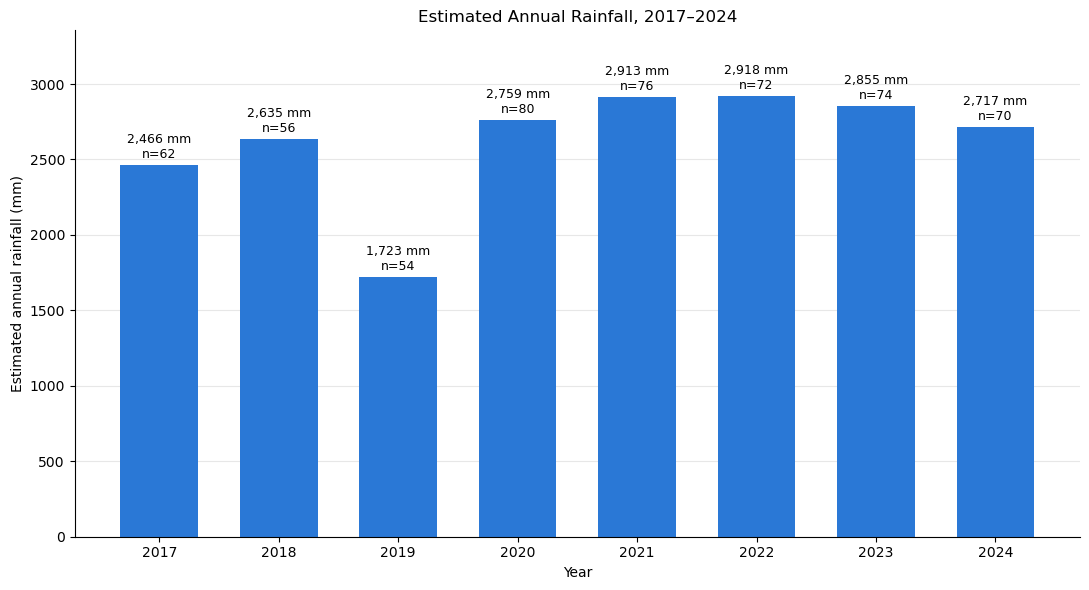

In [7]:


# Step 1: Calculate mean rainfall per observed interval for each year
# The year column was created in section 1.3
annual_spk = (
    rain.filter(F.col("year").between(2017, 2024))
        .groupBy("year")
        .agg(
            F.avg("reading_value").alias("mean_per_interval"),
            F.countDistinct("station_id").alias("n_stations")
        )
        # Within 2017–2024, 2020 and 2024 are leap years
        .withColumn(
            "days",
            F.when(F.col("year") % 4 == 0, 366).otherwise(365)
        )
        # Scale the observed mean to a full year:
        # days × 24 hours × 12 five-minute intervals per hour
        .withColumn(
            "est_annual_mm",
            F.col("mean_per_interval") * F.col("days") * RF_MULTIPLIER
        )
        .orderBy("year")
)

# Step 2: Display the annual estimates
annual_spk.show(truncate=False)

# Step 3: Convert the small annual summary to pandas
annual_df = annual_spk.toPandas()

# Step 4: Plot one bar for each year
fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    annual_df["year"],
    annual_df["est_annual_mm"],
    color="#2a78d6",
    width=0.65
)

# Step 5: Label each bar with its rainfall estimate and station count
for bar, rainfall, n in zip(
    bars,
    annual_df["est_annual_mm"],
    annual_df["n_stations"]
):
    ax.annotate(
        f"{rainfall:,.0f} mm\nn={n}",
        xy=(bar.get_x() + bar.get_width() / 2, rainfall),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

ax.set_xlabel("Year")
ax.set_ylabel("Estimated annual rainfall (mm)")
ax.set_title("Estimated Annual Rainfall, 2017–2024")
ax.set_xticks(annual_df["year"])
ax.margins(y=0.15)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

- **2019 has the lowest estimated annual rainfall**, at **1,723 mm**, standing out as substantially drier than the other years in this comparison.
- **2022 has the highest estimate**, at **2,918 mm**, closely followed by **2021 at 2,913 mm**.
- Estimated rainfall rises sharply after 2019, remains relatively high during 2020–2023, and decreases to **2,717 mm in 2024**.
- The results show **year-to-year variation rather than a steady increase or decrease** over the eight-year period.
- The number of reporting stations varies from **54 to 80**. Changes in station composition and missing observations may influence these estimates, so the differences cannot be attributed entirely to weather without further coverage checks.

### 1.4.2 Which Months Stand Out Within Individual Years?

Following the annual comparison, the monthly timeline identifies wetter months, drier periods and unusual peaks within each year from 2017 to 2024.

Unlike Section 1.3, which averages the same calendar month across years, this chart keeps all 96 year–months separate. It shows how individual years follow or depart from the typical seasonal pattern and reveals monthly variation hidden by the annual estimates.

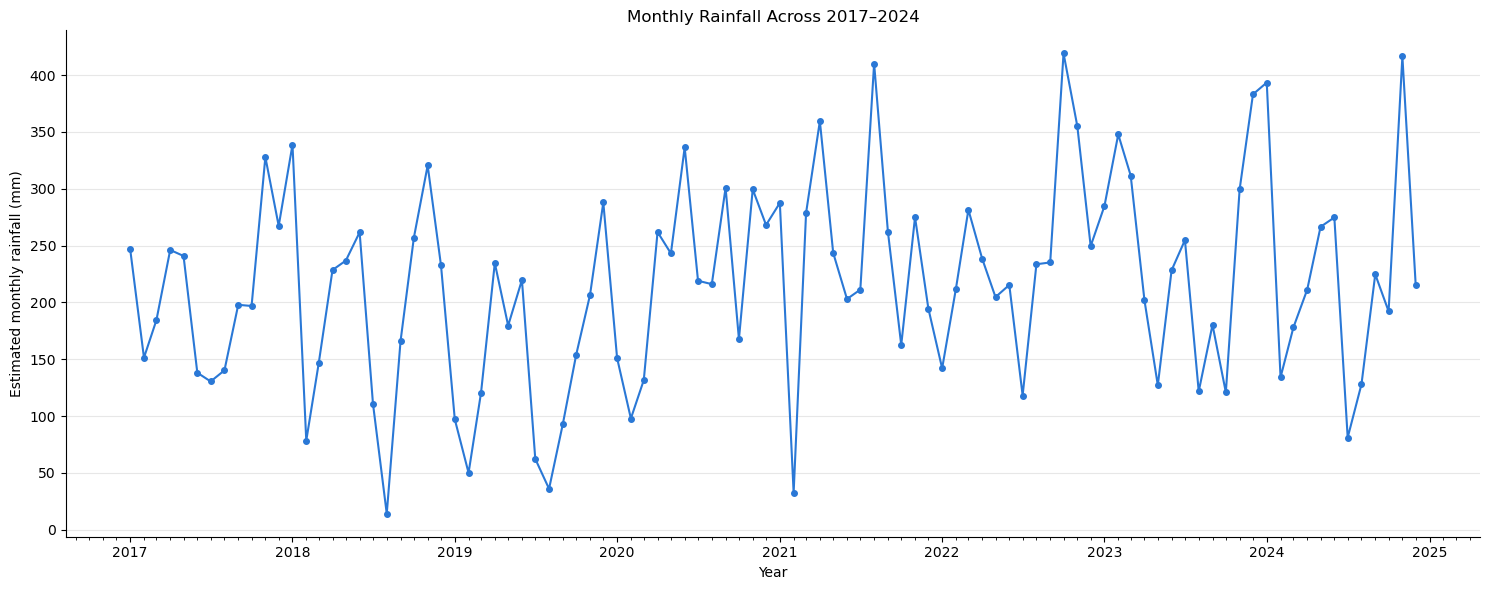

In [8]:
# Step 1: Retrieve the monthly estimates in chronological order
# Keep all 96 year-months, rather than averaging them into 12 calendar months
monthly_df = (
    monthly_spk.orderBy("year_month")
        .toPandas()
)

monthly_df["year_month"] = pd.to_datetime(monthly_df["year_month"])

# Step 2: Plot estimated rainfall for each month from 2017 to 2024
fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(
    monthly_df["year_month"],
    monthly_df["avg_rainfall_monthly"],
    marker="o",
    markersize=4,
    linewidth=1.5,
    color="#2a78d6"
)

# Step 3: Label the timeline by year, with smaller ticks for individual months
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.xaxis.set_minor_locator(mdates.MonthLocator())

ax.set_xlabel("Year")
ax.set_ylabel("Estimated monthly rainfall (mm)")
ax.set_title("Monthly Rainfall Across 2017–2024")

ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

- Estimated monthly rainfall fluctuates substantially, ranging from **below 50 mm to over 400 mm**, showing considerable variation within and between years.
- Several relatively low-rainfall months occur in **2019**, consistent with its lower annual rainfall estimate.
- Prominent monthly peaks exceeding **400 mm** occur in **2021, 2022 and 2024**.
- Although the seasonal profile shows November as the wettest month on average, individual years differ in the timing and size of their rainfall peaks.
- The timeline shows repeated rises and falls rather than a steady upward or downward pattern. Annual averages therefore conceal substantial month-to-month variation.
- These are estimates based on available readings. Very low monthly values should be interpreted cautiously because missing observations or changes in station coverage may also affect them.

## 1.5 Regional Variation: Do Regions Follow Similar Rainfall Patterns?

Following the annual comparison in Section 1.4, we examine monthly rainfall across the Central, East, North, South and West regions from 2017 to 2024. This reveals wetter and drier periods within individual years and differences between locations.

In [9]:
stations_spk = rain.select("station_id", "station_name_clean", "location_latitude", "location_longitude").distinct()

stations = (stations_spk
    .withColumn("dy", F.col("location_latitude") - F.lit(C_LAT))
    .withColumn("dx", F.col("location_longitude") - F.lit(C_LON))
    .withColumn("dist", F.sqrt(F.col("dx")**2 + F.col("dy")**2))
    .withColumn("bearing", F.degrees(F.atan2("dx", "dy")))  # 0=N, 90=E
    .withColumn("region",
        F.when(F.col("dist") < 0.045, "Central")
         .when((F.col("bearing") >= -45) & (F.col("bearing") < 45), "North")
         .when((F.col("bearing") >= 45) & (F.col("bearing") < 135), "East")
         .when((F.col("bearing") >= -135) & (F.col("bearing") < -45), "West")
         .otherwise("South")))

In [10]:
stations.groupBy("region").agg(F.count("*").alias("n"),
         F.round(F.avg("location_latitude"), 4).alias("mean_lat"),
         F.round(F.avg("location_longitude"), 4).alias("mean_lon")).orderBy(F.desc("n")).show()

+-------+---+--------+--------+
| region|  n|mean_lat|mean_lon|
+-------+---+--------+--------+
|   East| 29|  1.3502|103.9236|
|   West| 23|  1.3413|103.7139|
|  South| 15|  1.2801|103.8134|
|Central| 13|  1.3446|103.8263|
|  North| 11|  1.4305|103.8006|
+-------+---+--------+--------+



### 1.5.1 Comparing Regions Together

The combined line chart shows whether rainfall peaks and troughs occur at similar times across regions and how their rainfall amounts differ in the same month.

In [11]:
region_spk = rain.join(stations.select("station_id", "region"), on="station_id", how="left")

In [12]:
station_monthly = (region_spk
    .groupBy("station_id", "region", "year", "month")
    .agg(F.sum("reading_value").alias("monthly_mm")))

region_monthly = (station_monthly
    .groupBy("region", "year", "month")
    .agg(F.avg("monthly_mm").alias("avg_mm"),
         F.countDistinct("station_id").alias("n_stations"))
    .withColumn("ym", F.make_date("year", "month", F.lit(1)))
    .orderBy("ym", "region"))

region_df = region_monthly.toPandas()

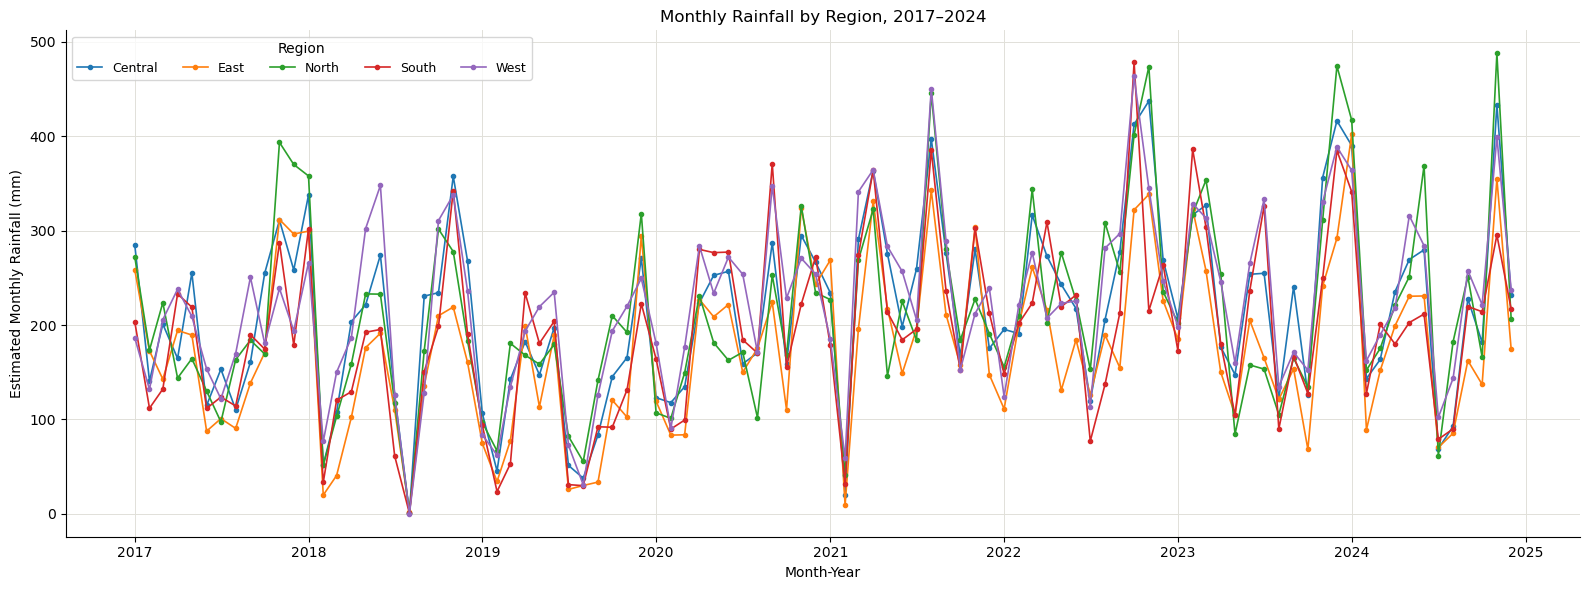

In [13]:
region_df = region_df.sort_values("ym")
wide = region_df.pivot(index="ym", columns="region", values="avg_mm")

fig, ax = plt.subplots(figsize=(16, 6))
wide.plot(ax=ax, marker="o", markersize=3, linewidth=1.2)

ax.set_xlabel("Month-Year")
ax.set_ylabel("Estimated Monthly Rainfall (mm)")
ax.set_title("Monthly Rainfall by Region, 2017–2024")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(which="major", axis="both", color="#e1e0d9", linewidth=0.7)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Region", ncol=5, fontsize=9)
plt.tight_layout()

- **Regions often rise and fall together**, suggesting that many wetter and drier months are shared across Singapore.
- **Rainfall amounts differ between regions.** In late 2024, the North peaks at approximately **490 mm**, compared with around **300 mm** in the South.
- **The North records several prominent peaks**, particularly towards the end of 2022, 2023 and 2024. However, no region consistently records the highest rainfall every month.
- **The East often records lower monthly rainfall** than the other regions, although this pattern is not consistent throughout the period.
- **Several months in 2019 show low rainfall across all five regions**, supporting the lower annual estimate observed in Section 1.4.
- **Near-zero values in 2018 require a check of observation coverage** before they can be interpreted as exceptionally dry conditions.

### 1.5.2 Examining Each Region Separately

Separate panels display the same data with less overlap, making each region’s monthly changes easier to follow. Shared time and rainfall scales allow comparisons of the timing and size of peaks across regions.

array([<Axes: xlabel='ym'>, <Axes: xlabel='ym'>, <Axes: xlabel='ym'>,
       <Axes: xlabel='ym'>, <Axes: xlabel='ym'>], dtype=object)

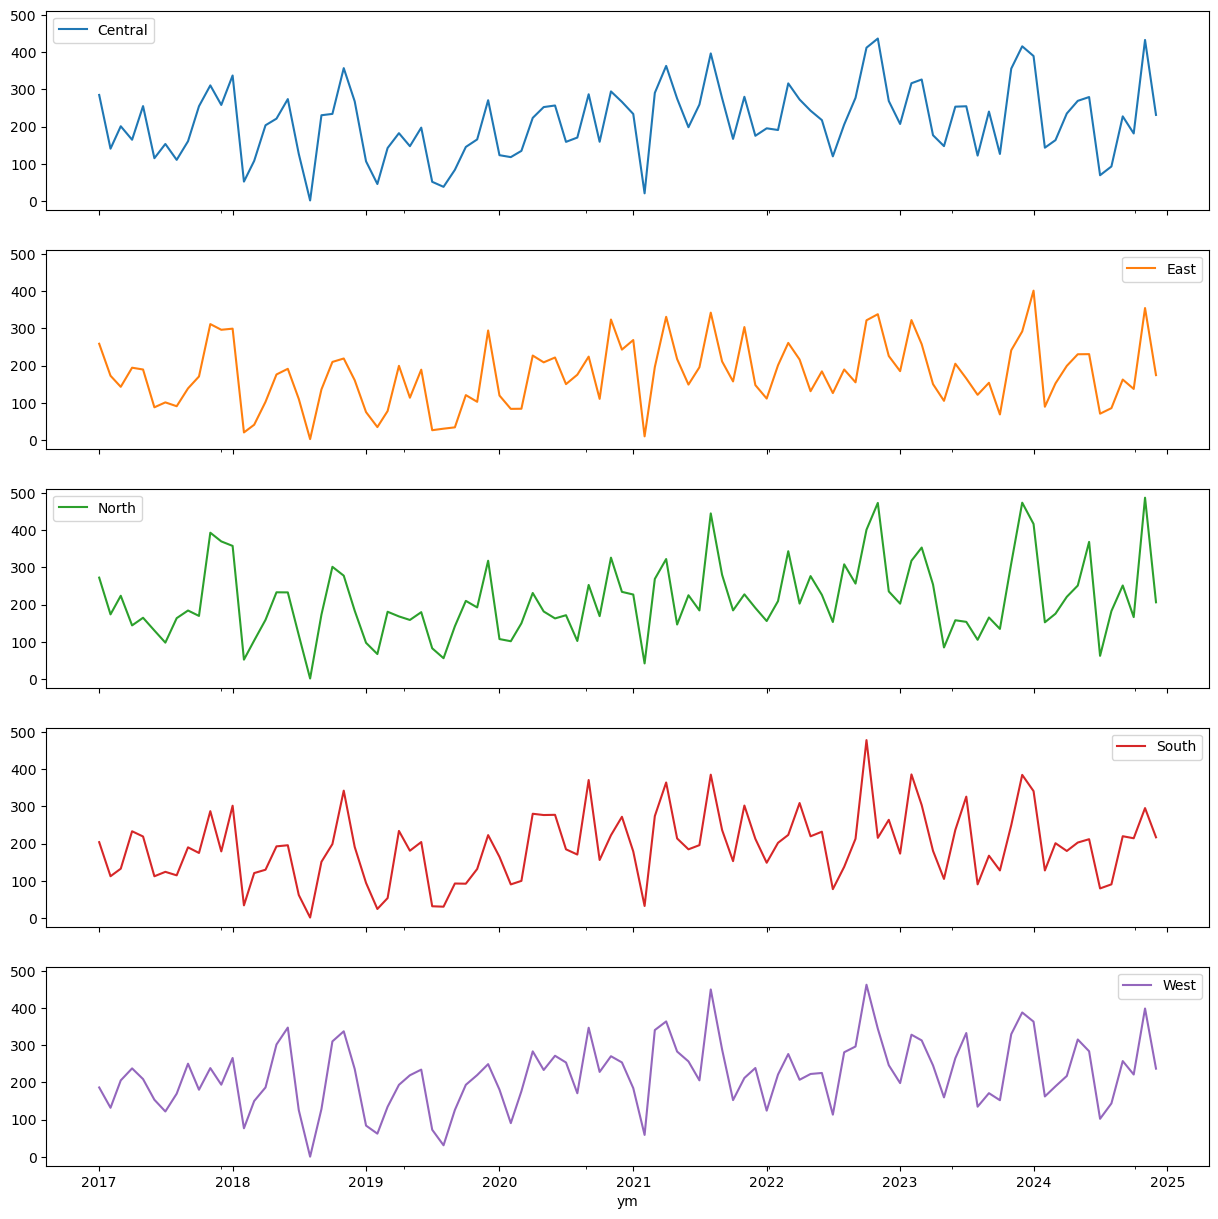

In [13]:
single_region = region_df.pivot(index="ym", columns="region", values="avg_mm")
single_region.plot(subplots=True, figsize=(15,15), sharex=True, sharey=True)

- **Central:** Several monthly peaks exceed 400 mm towards the end of 2022, 2023 and 2024, separated by substantially drier periods.
- **East:** Monthly rainfall is often lower than in other regions, with most peaks below 350 mm. A larger peak reaches approximately 400 mm near the end of 2023.
- **North:** Prominent peaks approach 450–490 mm in several years, showing substantial differences between wetter and drier months.
- **South:** The largest peak occurs in late 2022 at approximately 480 mm. Peaks in 2024 are less pronounced than those in the Central and North regions.
- **West:** Large peaks occur in 2021 and late 2022, reaching approximately 450–460 mm, while many other months fall between 150 and 300 mm.
- **Overall:** The regions share several peaks and troughs, but their magnitudes differ. None shows a steady increase or decrease throughout 2017–2024.

## 1.6 Time-of-Day Patterns: How Does Rainfall Vary by Hour and Month?

This section examines how rainfall varies by hour of day and calendar month across 2017–2024.

The heatmap shows the mean rainfall per observed five-minute interval for each month–hour combination, combining readings across stations and years. Darker colours indicate larger average rainfall amounts, helping identify whether the daily rainfall pattern changes through the year.

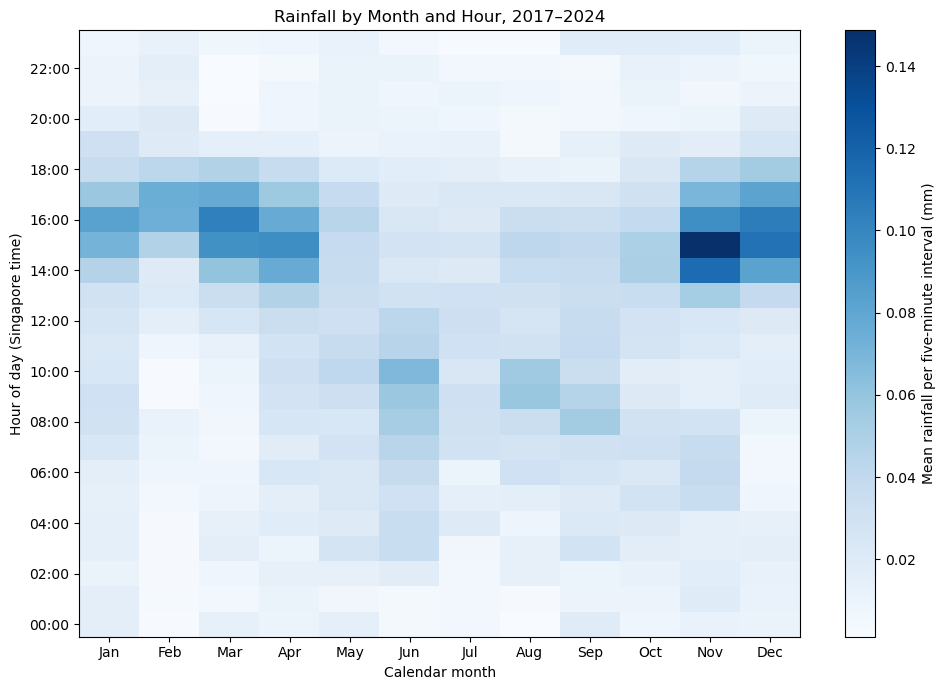

In [15]:
# Step 1: Interpret observation hours in Singapore time
# Assumes timestamp has already been converted to a timestamp type
spark.conf.set("spark.sql.session.timeZone", "Asia/Singapore")

# Step 2: Group readings by calendar month and hour of day
hour_month_spk = (
    rain.filter(F.year("timestamp").between(2017, 2024))
        .withColumn("month", F.month("timestamp"))
        .withColumn("hour", F.hour("timestamp"))
        .groupBy("month", "hour")
        .agg(
            F.avg("reading_value").alias("mean_interval_mm"),
            F.count("*").alias("n_readings")
        )
        .orderBy("month", "hour")
)

# Step 3: Convert the small summary to pandas
hour_month_df = hour_month_spk.toPandas()

# Step 4: Arrange the results into a grid
# Rows = hours; columns = calendar months
# Missing combinations remain blank rather than becoming zero
grid = (
    hour_month_df.pivot(
        index="hour",
        columns="month",
        values="mean_interval_mm"
    )
    .reindex(index=range(24), columns=range(1, 13))
)

# Step 5: Plot the heatmap
fig, ax = plt.subplots(figsize=(10, 7))

im = ax.imshow(
    grid.values,
    aspect="auto",
    origin="lower",
    cmap="Blues"
)

month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

ax.set_xticks(range(12))
ax.set_xticklabels(month_labels)

ax.set_yticks(range(0, 24, 2))
ax.set_yticklabels([f"{h:02d}:00" for h in range(0, 24, 2)])

ax.set_xlabel("Calendar month")
ax.set_ylabel("Hour of day (Singapore time)")
ax.set_title("Rainfall by Month and Hour, 2017–2024")
ax.grid(False)

fig.colorbar(
    im,
    ax=ax,
    label="Mean rainfall per five-minute interval (mm)"
)

plt.tight_layout()
plt.show()

- **Afternoon rainfall is prominent**, particularly around **14:00–17:00** in January–April and November–December.
- **November shows the strongest afternoon peak**, especially around **15:00**, where the mean rainfall per five-minute interval is highest.
- **Morning rainfall is relatively more prominent in June, August and September**, particularly around **08:00–11:00**, showing that the daily rainfall pattern varies by month.
- Overnight hours generally have lower mean rainfall than the main daytime peaks.
- These patterns suggest that **month and hour together** may be useful predictors for Task 2.
- The colours represent **average five-minute rainfall amounts**, not the probability of rain. Higher averages may reflect more frequent rain, larger amounts when it rains, or both.


## 1.7 Rainfall Frequency and Intensity: Does It Rain More Often or More Heavily?

Rainfall totals alone do not show whether rain occurs more often or falls in larger amounts.

We therefore compare two measures for each month:
- **Frequency:** The percentage of five-minute readings with rainfall greater than zero.
- **Intensity:** The average rainfall amount among those positive readings.

Together, these measures help explain differences in rainfall between months.

+-----+----------+---------------+--------------------+------------------+
|month|n_readings|n_wet_intervals|mean_wet_interval_mm|wet_interval_pct  |
+-----+----------+---------------+--------------------+------------------+
|1    |3903365   |171005         |0.623415133709637   |4.380963604479724 |
|2    |3679904   |77716          |0.8637931706470481  |2.111902919206588 |
|3    |4057990   |102734         |0.9508237945569603  |2.5316474412209   |
|4    |3784146   |106909         |1.023996099299559   |2.8251816922497177|
|5    |4067817   |101133         |0.9727182920512106  |2.4861737880538874|
|6    |4029868   |126141         |0.872750684075865   |3.1301521538670745|
|7    |4220080   |81872          |0.8934188975474852  |1.940058008378988 |
|8    |3739148   |89466          |0.8935015965843145  |2.3926841087862796|
|9    |4259809   |118822         |0.8892659172545336  |2.789373889768297 |
|10   |4380392   |120363         |0.8596047800403944  |2.7477677796872975|
|11   |4110296   |167496 

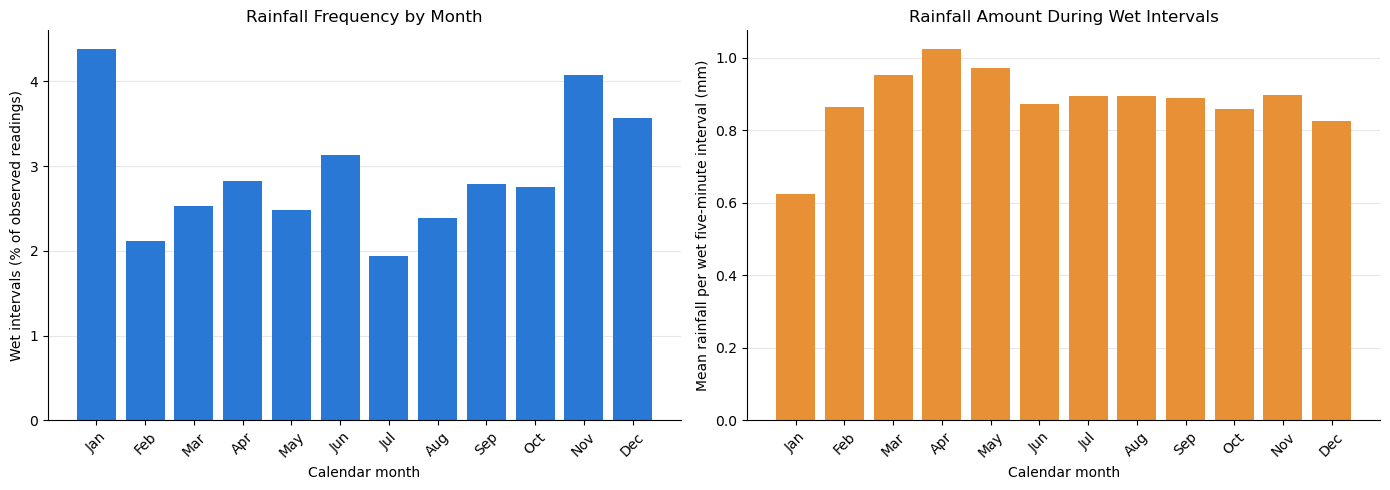

In [16]:

# Step 1: Summarise readings by calendar month across 2017–2024
# For example, all January readings are grouped together
rainfall_frequency_intensity = (
    rain.filter(F.year("timestamp").between(2017, 2024))
        .withColumn("month", F.month("timestamp"))
        .groupBy("month")
        .agg(
            # Count observed rainfall values, excluding nulls
            F.count("reading_value").alias("n_readings"),

            # Count intervals where rainfall is greater than zero
            F.count(
                F.when(F.col("reading_value") > 0, 1)
            ).alias("n_wet_intervals"),

            # Average rainfall only across positive readings
            F.avg(
                F.when(
                    F.col("reading_value") > 0,
                    F.col("reading_value")
                )
            ).alias("mean_wet_interval_mm")
        )
        # Step 2: Express wet intervals as a percentage of observed readings
        .withColumn(
            "wet_interval_pct",
            F.when(
                F.col("n_readings") > 0,
                100.0 * F.col("n_wet_intervals") / F.col("n_readings")
            )
        )
        .orderBy("month")
)

# Step 3: Display the calculated results
rainfall_frequency_intensity.show(12, truncate=False)

# Step 4: Convert the small summary to pandas
# Keep missing months as missing values rather than filling them with zero
fi_df = (
    rainfall_frequency_intensity.toPandas()
        .set_index("month")
        .reindex(range(1, 13))
)

# Step 5: Plot frequency and intensity separately because their units differ
month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left chart: How often is rain recorded?
axes[0].bar(
    fi_df.index,
    fi_df["wet_interval_pct"],
    color="#2a78d6"
)
axes[0].set_title("Rainfall Frequency by Month")
axes[0].set_ylabel("Wet intervals (% of observed readings)")

# Right chart: How much rain falls during a wet interval?
axes[1].bar(
    fi_df.index,
    fi_df["mean_wet_interval_mm"],
    color="#e89036"
)
axes[1].set_title("Rainfall Amount During Wet Intervals")
axes[1].set_ylabel("Mean rainfall per wet five-minute interval (mm)")

for ax in axes:
    ax.set_xlabel("Calendar month")
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_labels, rotation=45)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

- **January has the highest rainfall frequency**, with approximately **4.4%** of observed intervals recording rain. However, it has the **lowest mean amount per wet interval**, at around **0.62 mm**. Rain is recorded relatively often, but in smaller amounts.
- **April has the highest mean rainfall per wet interval**, at approximately **1.02 mm**, although its wet-interval frequency is lower than January’s. This indicates larger amounts when rain occurs.
- **November combines relatively high frequency and intensity**, with around **4.1%** wet intervals and **0.9 mm** per wet interval. This is consistent with its high estimated monthly rainfall.
- **July has the lowest wet-interval frequency**, at approximately **1.8%**, despite averaging around **0.9 mm** when rain is recorded. Its relatively low monthly rainfall is therefore associated with fewer wet intervals.
- These results show that **frequent rainfall does not necessarily mean heavier rainfall**. Both frequency and the amount recorded during wet intervals help explain monthly differences.
- The percentages describe observed station-level five-minute readings, not the percentage of rainy days or the number of separate storms.

## 1.8 Rainfall Persistence: How Strongly Is Rainfall Related to Recent Readings?

This section examines whether rainfall at a station is related to rainfall recorded at the same station earlier.

We calculate autocorrelation at different time lags. For example, a five-minute lag compares current rainfall with the reading five minutes earlier. A higher positive correlation indicates that the two readings tend to vary together.

Comparing correlations across lags shows how this relationship weakens as readings become further apart. This helps identify recent-rainfall features to consider for Task 2, although their predictive value must be tested during model evaluation.

In [17]:
rain_lag = rain.withColumn("ts_long", F.col("timestamp").cast("long"))

w = Window.partitionBy("station_id").orderBy("ts_long")

lags = {"lag_5m": 1, "lag_30m": 6, "lag_1h": 12, "lag_1d": 288}

for name, k in lags.items():
    rain_lag = (rain_lag
        .withColumn(name, F.lag("reading_value", k).over(w))
        .withColumn(name + "_ts", F.lag("ts_long", k).over(w)))
    
    # null out where the gap isn't the expected duration
    rain_lag = rain_lag.withColumn(name,
        F.when(F.col("ts_long") - F.col(name + "_ts") == k * 300,
               F.col(name)))
    rain_lag = rain_lag.drop(name + "_ts")

rain_lag.select([F.corr("reading_value", c).alias(c) for c in lags]).show()

+------------------+-------------------+-------------------+-------------------+
|            lag_5m|            lag_30m|             lag_1h|             lag_1d|
+------------------+-------------------+-------------------+-------------------+
|0.7936663864725976|0.23556500544556316|0.09441363467952034|0.01529208530378663|
+------------------+-------------------+-------------------+-------------------+



In [18]:
acf = []
for k in range(1, 15):
    c = (rain_lag.withColumn("lv", F.lag("reading_value", k).over(w))
           .withColumn("lt", F.lag("ts_long", k).over(w))
           .filter(F.col("ts_long") - F.col("lt") == k * 300)
           .select(F.corr("reading_value", "lv")).first()[0])
    acf.append((k * 5, c))

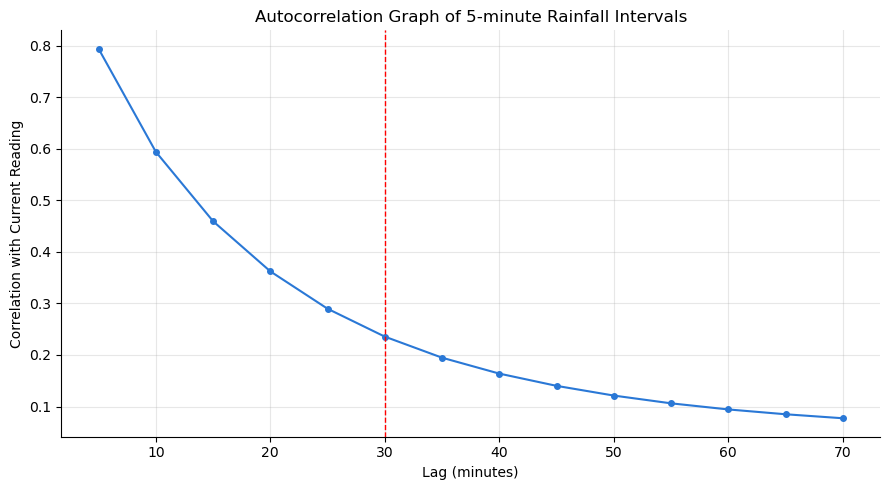

In [20]:
mins = [m for m, _ in acf]
vals = [v for _, v in acf]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(mins, vals, marker="o", markersize=4, color="#2a78d6")
ax.axvline(30, color="#FF0000", linestyle="--", linewidth=1)
ax.set_xlabel("Lag (minutes)")
ax.set_ylabel("Correlation with Current Reading")
ax.set_title("Autocorrelation Graph of 5-minute Rainfall Intervals")
ax.grid(alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

- **Rainfall shows strong short-term persistence:** the correlation is approximately **0.79 at a five-minute lag**, indicating that current rainfall is closely related to the reading five minutes earlier.
- **The relationship weakens as the time gap increases**, falling to approximately **0.36 at 20 minutes** and **0.24 at 30 minutes**.
- **By one hour, the correlation is around 0.09**, suggesting a much weaker relationship with readings further in the past.
- **For Task 2, recent rainfall readings are promising candidate features**, particularly those from the preceding 5–30 minutes. Their predictive usefulness should be assessed during model evaluation.
- The **red dashed line marks 30 minutes**. The correlation at this lag compares individual five-minute readings 30 minutes apart; it does not directly measure how well we can predict the total rainfall over the next 30 minutes.

## 1.10 Implications for Task 2: Which Features Could Help Predict Rainfall?

Task 2 predicts the probability that rainfall at a station will exceed a chosen threshold in the next 30 minutes. The EDA motivates the following candidate features.

| Feature column | Original columns used | How to calculate | EDA motivation |
|---|---|---|---|
| `station_id` | `station_id` | Use the existing station ID. | Rainfall differs by location. |
| `month` | `timestamp` | Extract the month, from 1–12. | Rainfall varies seasonally. |
| `hour` | `timestamp` | Extract the hour in Singapore time, from 0–23. | Rainfall varies by time of day. |
| `rain_now`, `rain_lag_5m`, `rain_lag_10m` | `station_id`, `timestamp`, `reading_value` | Retrieve the same station’s readings at the prediction time, 5 minutes earlier and 10 minutes earlier. | Nearby readings are strongly correlated. |
| `rain_sum_15m`, `rain_sum_30m`, `rain_sum_60m` | `station_id`, `timestamp`, `reading_value` | Sum the same station’s rainfall over the previous 15, 30 and 60 minutes. | Recent accumulated rainfall may help predict upcoming rain. |
| `wet_count_30m`, `wet_count_60m` | `station_id`, `timestamp`, `reading_value` | Count readings greater than zero over the previous 30 and 60 minutes. | Rainfall frequency provides information beyond rainfall amount. |
| `threshold_mm` | New input | Supply the rainfall threshold, such as 1 mm or 5 mm. | Required by Task 2. |

### Creating the Target Label

For each station and prediction time, sum the next six consecutive five-minute readings to obtain `future_rain_30m`.

- **Label = 1:** `future_rain_30m > threshold_mm`.
- **Label = 0:** `future_rain_30m <= threshold_mm`.

The model estimates the probability of **label 1**. Future rainfall is used only to create the label, never as an input feature.

All features must use readings available at prediction time. Time windows must be checked for missing observations. Candidate features and window lengths will be evaluated using Spark MLlib, training on earlier data and testing on later data.